In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import flopy
from flopy.utils.gridgen import Gridgen
import pandas as pd
import pyemu
import shutil
import numpy as np
flopy.__version__

'3.11.0'

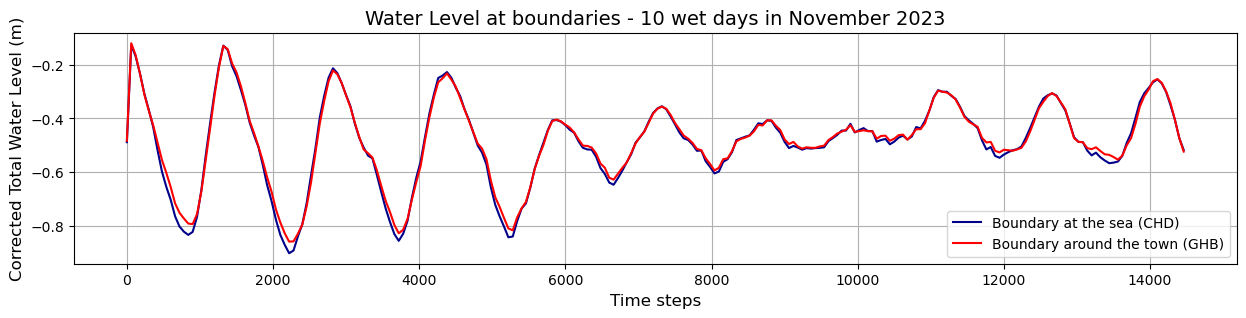

In [ ]:
twl_may = pd.read_csv(r"C:\SAN_FELIPE\SAN_FELIPE\forcing\CHD&GHB\05_Corrected_total_water_level_2023_november.csv")

plt.figure(figsize=(15, 3))

plt.plot(twl_may["PASO"]*60, twl_may["MAR"], label="Boundary at the sea (CHD)", color='darkblue')
plt.plot(twl_may["PASO"]*60, twl_may["COL1"], label="Boundary around the town (GHB)", color='red')

plt.xlabel("Time steps", fontsize=12)
plt.ylabel("Corrected Total Water Level (m)", fontsize=12)
plt.title("Water Level at boundaries - 10 wet days in November 2023", fontsize=14)
plt.legend()
plt.grid(True)

output_folder = r"C:\MDP\Figuren MODFLOW\Wet"
output_path = os.path.join(output_folder, "water_levels_november_2024.png")
plt.savefig(output_path, dpi=300, bbox_inches="tight")

plt.show()


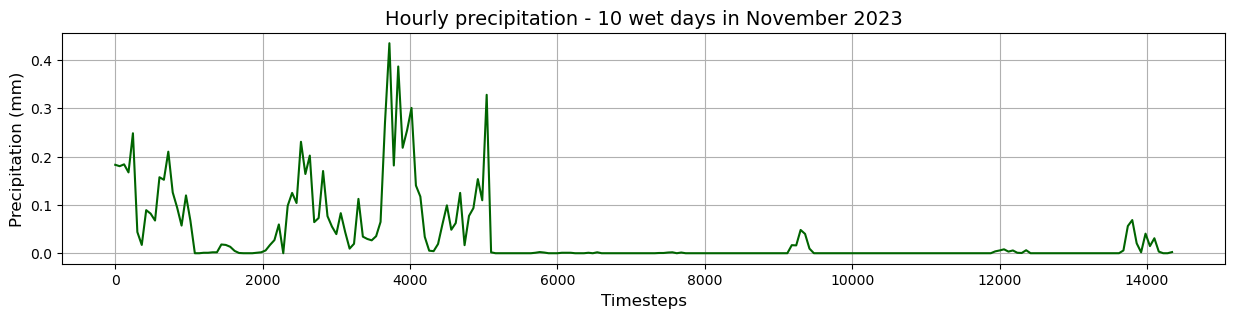

In [3]:
precip_may = pd.read_excel(r"C:\SAN_FELIPE\SAN_FELIPE\forcing\RCH\Precipitation_wet_november.xlsx")

plt.figure(figsize=(15, 3))

plt.plot(precip_may.index * 60, precip_may["tp_mm"], color='darkgreen')
plt.xlabel("Timesteps", fontsize=12)
plt.ylabel("Precipitation (mm)", fontsize=12)
plt.title("Hourly precipitation - 10 wet days in November 2023", fontsize=14)
plt.grid(True)

output_folder = r"C:\MDP\Figuren MODFLOW\Wet"
output_path = os.path.join(output_folder, "precipitation_november_2023.png")
plt.savefig(output_path, dpi=300, bbox_inches="tight")

plt.show()

## Below the outputs of modelmuse are called

In [ ]:
sim_source = r"C:\SAN_FELIPE\SAN_FELIPE\modelMuse_output"
sim_name = 'modflow'
exe_path = os.path.join(os.path.dirname(os.getcwd()), 'exe','mf6.exe')  
sim6 = flopy.mf6.MFSimulation.load(sim_name, exe_name=exe_path, sim_ws=sim_source)

loading simulation...
  loading simulation name file...
  loading tdis package...
  loading model gwf6...
    loading package dis...
    loading package ic...
    loading package npf...
    loading package oc...
    loading package chd...
    loading package rch...
  loading solution package modflow...


In [ ]:
gwf = sim6.get_model()
gwf.get_package_list()

['DIS', 'IC', 'NPF', 'OC', 'CHD-1', 'RCH-1']

In [ ]:
workspace= os.path.join(os.getcwd(), 'model_wet')     
model_name = 'SAN_FELIPE'

In [ ]:
sim = flopy.mf6.MFSimulation(sim_name=model_name, version="mf6", exe_name=exe_path, sim_ws=workspace)

In [ ]:
mf = flopy.mf6.ModflowGwf(sim, modelname=model_name, model_nam_file=f"{model_name}.nam")
mf.name_file.save_flows = True

In [9]:
# Parameters for calibration
k = 5.54e-4 * 60 #m/min

# conducatance uses in GHB. cond = K * (W*L/D), where A is the area of the cell (5(cell size)*6(depth aquifer)) and L is the length of the cell (5m).
cond2 = k * ((5*6)/1000)

**For the Time discretization (TDIS)**

In [ ]:
df = pd.read_csv(r"C:\SAN_FELIPE\SAN_FELIPE\forcing\CHD&GHB\05_Corrected_total_water_level_2023_november.csv")
num_records = len(df) 
print(num_records)

pname = 'tdis'
time_units = 'minutes'
len_sptran = 60.0 
int_tran = 5      

include_steady_period = True 

if include_steady_period:
    nper = num_records  # 1 steady-state + 240 hourly transient periods
    perlen = np.ones(nper) * len_sptran
    nstp = np.ones(nper, dtype=int) * int_tran
    tsmult = np.ones(nper)
    perlen[0] = 1.0  # Length does not affect steady-state solution
    nstp[0] = 1
else:
    nper = num_records  # 240 transient stress periods
    
    perlen = np.ones(nper) * len_sptran
    nstp = np.ones(nper, dtype=int) * int_tran
    tsmult = np.ones(nper)

perioddata = list(zip(perlen, nstp, tsmult))

tdis = flopy.mf6.ModflowTdis(
    sim, 
    pname=pname, 
    time_units=time_units, 
    nper=nper, 
    perioddata=perioddata
)
print(nper)

242
242


**Iterative Model Solver (IMS) => I did not change anything here**

In [ ]:
ims6 = sim6.get_package('ims') 
pname = 'ims'
print_option = ims6.print_option.get_data()
complexity = None  
outer_dvclose = 0.01 
outer_maximum = 150 
under_relaxation = None
inner_maximum = 250 
inner_dvclose = 0.001 
linear_acceleration = 'cg' 
scaling_method = None 
reordering_method = None 
relaxation_factor = 0.97 
ims = flopy.mf6.ModflowIms(sim, pname=pname, print_option=print_option, complexity=complexity, outer_dvclose=outer_dvclose, outer_maximum=outer_maximum, 
                           under_relaxation=under_relaxation, inner_maximum=inner_maximum, inner_dvclose=inner_dvclose, 
                           linear_acceleration=linear_acceleration, scaling_method=scaling_method, reordering_method=reordering_method, 
                           relaxation_factor=relaxation_factor)

sim.register_ims_package(ims, [mf.name])

**Spatial Discretization (DIS)**

In [ ]:
dis6 = gwf.get_package('dis')
pname = 'dis'
length_units = dis6.length_units.get_data()
nogrb = dis6.nogrb.get_data()
xorigin = dis6.xorigin.get_data()
yorigin = dis6.yorigin.get_data()
angrot = dis6.angrot.get_data()
nlay = dis6.nlay.get_data()
nrow = dis6.nrow.get_data()
ncol = dis6.ncol.get_data()
delr = dis6.delr.get_data()
delc = dis6.delc.get_data()
top = dis6.top.get_data()
botm = dis6.botm.get_data()
idomain = dis6.idomain.get_data()

dis = flopy.mf6.ModflowGwfdis(mf, pname=pname, length_units=length_units, nogrb=nogrb, xorigin=xorigin, yorigin=yorigin, angrot=angrot, nlay=nlay, 
                              nrow=nrow, ncol=ncol, delr=delr, delc=delc, top=top, botm=botm, idomain=idomain)

**Make a plot to show the spatial discretization**

C:\Users\Davida van Krimpen\AppData\Local\Temp\ipykernel_16076\333737425.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


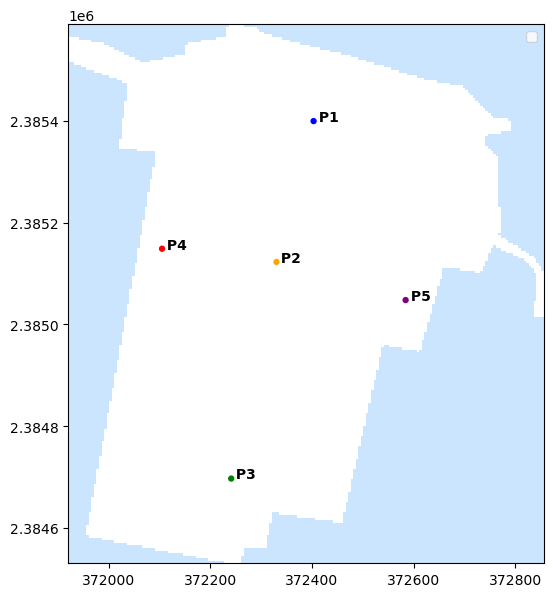

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(50, 7))
mapview = flopy.plot.PlotMapView(model=mf)
pltinact = mapview.plot_inactive(color_noflow="#CCE5FF")

P1 = [372403, 2385400]
P2 = [372330, 2385123]
P3 = [372241, 2384697]
P4 = [372105, 2385149]
P5 = [372584, 2385048]
x_locs = [P1[0], P2[0], P3[0], P4[0], P5[0]]

y_locs = [P1[1], P2[1], P3[1], P4[1], P5[1]]
c = ['blue', 'orange', 'green', 'red', 'purple']
ax.scatter(x_locs, y_locs, color=c, s=50, marker=".", zorder=5)


for i, (x, y) in enumerate(zip(x_locs, y_locs)):
    ax.annotate(
        f" P{i+1}", (x, y), fontsize=10, fontweight="bold", color="black" )

plt.legend(loc="upper right")

In [14]:
import pandas as pd


results = []

for x, y in zip(x_locs, y_locs):
    row, col = mf.modelgrid.intersect(x, y)
    dx = mf.modelgrid.delr[col]
    dy = mf.modelgrid.delc[row]
    
    results.append({
        'x': x,
        'y': y,
        'row': row,
        'col': col
    })

df_results = pd.DataFrame(results)
print(df_results)

        x        y  row  col
0  372403  2385400   38   96
1  372330  2385123   93   81
2  372241  2384697  178   64
3  372105  2385149   88   36
4  372584  2385048  108  132


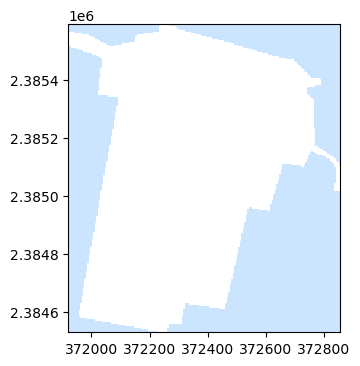

In [ ]:
fig, ax = plt.subplots(figsize=(20,4)) 
mapview = flopy.plot.PlotMapView(model=mf)
pltinact = mapview.plot_inactive(color_noflow='#CCE5FF') 


**Initial condition (IC)**

In [ ]:
import scipy
h_inicial = top

ic6 = gwf.get_package('ic')
pname = 'ic'
strt = h_inicial

ic = flopy.mf6.ModflowGwfic(mf, pname=pname, strt=strt)

**Node property flow (NPF)**

In [ ]:
npf6 = gwf.get_package('npf')
pname = 'npf'
save_flows = npf6.save_flows.get_data()
save_specific_discharge = npf6.save_specific_discharge.get_data()
icelltype = 1 #convertible cell type
k = k
k22 = k
k33 = k/10

npf = flopy.mf6.ModflowGwfnpf(mf, pname=pname,save_flows=save_flows, save_specific_discharge=save_specific_discharge, icelltype=icelltype, k=k,
                              k22=k22, k33=k33)

**Observation (OBS) package => not used since no observation data available** => can be used to calculate the head variance over time for a certain cell => do this!!

In [ ]:
pname = 'obs'
digits = 8
continous = {model_name+'.ob_gw_out_head.csv':[('P1', 'head', (0, 38, 96)), ('P2', 'head', (0, 93, 81)), ('P3', 'head', (0, 178, 64)),
                                              ('P4', 'head', (0, 88, 36)), ('P5', 'head', (0, 108, 132))]}
                                              

obs = flopy.mf6.ModflowUtlobs(mf, pname=pname, digits=digits, continuous=continous)

**Storage (STO) package => I did not change anything here**

In [ ]:
steady_state = {e:True for e in range(0,1)} 

transient = {e:True for e in range(1,nper)} 
iconvert = 1 
sy = 0.26 
ss = 1.5e-4 / 0.3 

sto = flopy.mf6.modflow.mfgwfsto.ModflowGwfsto(mf, steady_state=steady_state, transient=transient, iconvert=iconvert, sy=sy, ss=ss)

**Output control (OC) package=> did not change anything here**

In [ ]:
oc6 = gwf.get_package('oc')
pname = 'oc'
budget_filerecord = model_name + '.cbc'
head_filerecord = model_name + '.bhd'
saverecord = {e:[("HEAD", 'LAST'), ("BUDGET", 'LAST')]for e in range(nper)}
printrecord = {e:[("HEAD", "LAST"), ('BUDGET','LAST')] for e in range(nper)}


oc = flopy.mf6.ModflowGwfoc(mf, pname=pname, budget_filerecord=budget_filerecord, head_filerecord=head_filerecord, saverecord=saverecord, 
                            printrecord=printrecord)

**Call Gridgen where I placed this .exe document**

In [ ]:
gridgen_exe = os.path.join(os.getcwd(), 'gridgen_x64.exe')
g = Gridgen(dis, model_ws=workspace, exe_name = gridgen_exe)
g.build()


c:\Anaconda\Lib\site-packages\flopy\utils\gridgen.py:232: UserWarning: Supplying a dis object is deprecated, and support will be removed in version 3.3.7. Please supply StructuredGrid.


**Collect data for boundary conditions CHD and GHB**

In [23]:
file_path = r"C:\SAN_FELIPE\SAN_FELIPE\forcing\CHD&GHB\05_Corrected_total_water_level_2023_november.csv"
h_bound = pd.read_csv(file_path, index_col=0, header=0)
h_bound.info()

<class 'pandas.core.frame.DataFrame'>
Index: 242 entries, 0 to 241
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   MAR     242 non-null    float64
 1   COL1    242 non-null    float64
dtypes: float64(2)
memory usage: 5.7 KB


**The boundary condition at the sea side (total water head north west of San Felipe) CHD package**

In [ ]:
pname = 'chd'

chd_path = os.path.join(os.getcwd(), 'shapes')

chd_intersect = g.intersect(chd_path+'/Coastline', 'line', 0) 
chd_unique = np.unique(chd_intersect.nodenumber)

chd_rec = {} 

for sp in range(0,1): 
    chd_rec.setdefault(sp,[]) 
    h_chd = h_bound['MAR'][sp].item() 
    for ix in np.arange(chd_unique.shape[0]): 
        [(l,i,j)] = mf.modelgrid.get_lrc([chd_unique[ix]]) 
        if idomain[(l,i,j)] == 1: 
            chd_rec[sp].append(((l, i, j), h_chd)) 

for sp in range(1,nper): 
    chd_rec.setdefault(sp,[]) 
    h_chd = h_bound['MAR'][sp].item() 
    for ix in np.arange(chd_unique.shape[0]):
        [(l,i,j)] = mf.modelgrid.get_lrc([chd_unique[ix]]) 
        if idomain[(l,i,j)] == 1:
            chd_rec[sp].append(((l, i, j), h_chd)) 
            

maxbound = len(chd_rec[sp]) 

chd = flopy.mf6.ModflowGwfchd(mf, pname=pname, maxbound=maxbound, stress_period_data=chd_rec, save_flows=True)

**The boundary condition around the town (total water head east in mangrove used) GHB package**

In [ ]:
pname = 'ghb'

ghb_path = os.path.join(os.getcwd(), 'shapes') 

ghb_rec = {} 

ghb_intersect = g.intersect(ghb_path+'/Closedsystem1', 'line', 0)
ghb_unique = np.unique(ghb_intersect.nodenumber)

cond = cond2 

for sp in range(0,1):
    ghb_rec.setdefault(sp,[])
    h_ghb = h_bound['COL1'][sp].item()
    for ix in np.arange(ghb_unique.shape[0]): 
        [(l,i,j)] = mf.modelgrid.get_lrc([ghb_unique[ix]])
        if idomain[(l,i,j)] == 1:
            ghb_rec[sp].append(((l, i, j), h_ghb, cond))

for sp in range(1,nper):
    ghb_rec.setdefault(sp,[])
    h_ghb = h_bound['COL1'][sp].item()
    for ix in np.arange(ghb_unique.shape[0]): 
        [(l,i,j)] = mf.modelgrid.get_lrc([ghb_unique[ix]])
        if idomain[(l,i,j)] == 1:
            ghb_rec[sp].append(((l, i, j), h_ghb, cond))

maxbound = len(ghb_rec[sp]) 

ghb = flopy.mf6.ModflowGwfghb(mf, pname=pname, maxbound=maxbound, stress_period_data=ghb_rec, save_flows=True)

**Plot of the boundary condition**

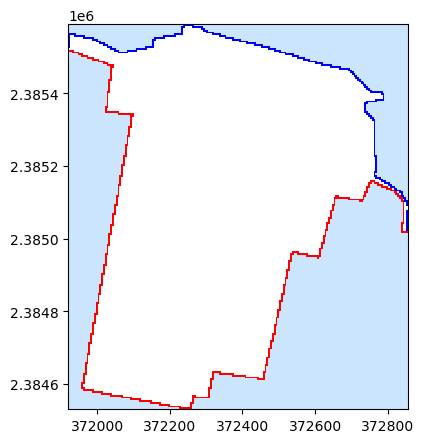

In [26]:
fig1, ax= plt.subplots(figsize=(30,5))
mapview = flopy.plot.PlotMapView(model=mf)
pltibd= mapview.plot_ibound(color_noflow='#CCE5FF')
pltchd = mapview.plot_bc('CHD', color='blue')
pltghb = mapview.plot_bc('GHB', color='red')

**Recharge package (RCH)**

In [ ]:
Cr = 0.4  

df_P = pd.read_excel(r"C:\SAN_FELIPE\SAN_FELIPE\forcing\RCH\Precipitation_wet_november.xlsx")

tp_hourly_mm = df_P["tp_mm"].values
print(f'length tp_hourly {len(tp_hourly_mm)}')


r_flux_series = (Cr * (tp_hourly_mm / 1000.0)) / 60.0  
print(f'lenght r_flux {len(r_flux_series)}')

offset = 1 if include_steady_period else 0
recharge = {}

if include_steady_period:
    recharge[0] = 0.0

for i, flux in enumerate(r_flux_series):
    sp = i + offset
    recharge[sp] = float(flux)

print(sp, flux)
print(len(recharge))

pname = "rch"

rch = flopy.mf6.ModflowGwfrcha(
    mf,                  
    pname=pname,
    readasarrays=True,
    save_flows=True,
    recharge=recharge,
)

recharge_keys = list(recharge.keys())

print(f'lenght recharge keys {len(recharge_keys)}')

print("Aantal perioden in RCH:", len(recharge_keys))          # Verwacht: 241
print("Lowest RCH periode index (Python):", min(recharge_keys))  # Verwacht: 0
print("Highest RCH periode index (Python):", max(recharge_keys)) # Verwacht: 240

length tp_hourly 240
lenght r_flux 240
240 1.5894571999999997e-08
241
lenght recharge keys 241
Aantal perioden in RCH: 241
Lowest RCH periode index (Python): 0
Highest RCH periode index (Python): 240


**Let the simulation start!**

In [28]:
sim.write_simulation()

writing simulation...
  writing simulation name file...
  writing simulation tdis package...
  writing solution package ims...
  writing model SAN_FELIPE...
    writing model name file...
    writing package dis...
    writing package ic...
    writing package npf...
    writing package obs...
    writing package sto...
    writing package oc...
    writing package chd...
    writing package ghb...
    writing package rch...


In [29]:
success, buff = sim.run_simulation(silent=False)

if not success:
    print("--- SIMULATION FAILED ---")
    for line in buff:
        print(line)

FloPy is using the following executable to run the model: ..\..\exe\mf6.exe
                                   MODFLOW 6
                U.S. GEOLOGICAL SURVEY MODULAR HYDROLOGIC MODEL
                     VERSION 6.8.0+8680167.dirty 09/02/2026

   MODFLOW 6 compiled Sep 02 2026 19:56:32 with Intel(R) Fortran Intel(R) 64
   Compiler Classic for applications running on Intel(R) 64, Version 2021.6.0
                             Build 20220226_000000

This software has been approved for release by the U.S. Geological 
Survey (USGS). Although the software has been subjected to rigorous 
review, the USGS reserves the right to update the software as needed 
pursuant to further analysis and review. No warranty, expressed or 
implied, is made by the USGS or the U.S. Government as to the 
functionality of the software and related material nor shall the 
fact of release constitute any such warranty. Furthermore, the 
software is released on condition that neither the USGS nor the U.S. 
Governmen

In [ ]:
import matplotlib.pyplot as plt
import flopy

gwf = sim.get_model()  

head_file = gwf.output.head()
times = head_file.get_times()
htimes = head_file.get_kstpkper()
heads_steady = head_file.get_data(totim=times[0])
heads_final = head_file.get_data(totim=times[-1])

print(htimes)


[(np.int32(0), np.int32(0)), (np.int32(4), np.int32(1)), (np.int32(4), np.int32(2)), (np.int32(4), np.int32(3)), (np.int32(4), np.int32(4)), (np.int32(4), np.int32(5)), (np.int32(4), np.int32(6)), (np.int32(4), np.int32(7)), (np.int32(4), np.int32(8)), (np.int32(4), np.int32(9)), (np.int32(4), np.int32(10)), (np.int32(4), np.int32(11)), (np.int32(4), np.int32(12)), (np.int32(4), np.int32(13)), (np.int32(4), np.int32(14)), (np.int32(4), np.int32(15)), (np.int32(4), np.int32(16)), (np.int32(4), np.int32(17)), (np.int32(4), np.int32(18)), (np.int32(4), np.int32(19)), (np.int32(4), np.int32(20)), (np.int32(4), np.int32(21)), (np.int32(4), np.int32(22)), (np.int32(4), np.int32(23)), (np.int32(4), np.int32(24)), (np.int32(4), np.int32(25)), (np.int32(4), np.int32(26)), (np.int32(4), np.int32(27)), (np.int32(4), np.int32(28)), (np.int32(4), np.int32(29)), (np.int32(4), np.int32(30)), (np.int32(4), np.int32(31)), (np.int32(4), np.int32(32)), (np.int32(4), np.int32(33)), (np.int32(4), np.int32(

In [31]:
help(head_file.get_data)

Help on method get_data in module flopy.utils.datafile:

get_data(kstpkper=None, idx=None, totim=None, mflay=None) method of flopy.utils.binaryfile.HeadFile instance
    Get data from the file for the specified conditions.

    Parameters
    ----------
    idx : int
        The zero-based record number. The first record is record 0.
    kstpkper : tuple of ints
        A tuple (kstep, kper) of zero-based time step and stress period.
    totim : float
        The simulation time.
    mflay : integer
       MODFLOW zero-based layer number to return.  If None, then all
       all layers will be included. (Default is None.)

    Returns
    -------
    data : numpy array
        Array has size (nlay, nrow, ncol) if mflay is None or it has size
        (nrow, ncol) if mlay is specified.

    Notes
    -----
    If both kstpkper and totim are None, the last entry will be returned.



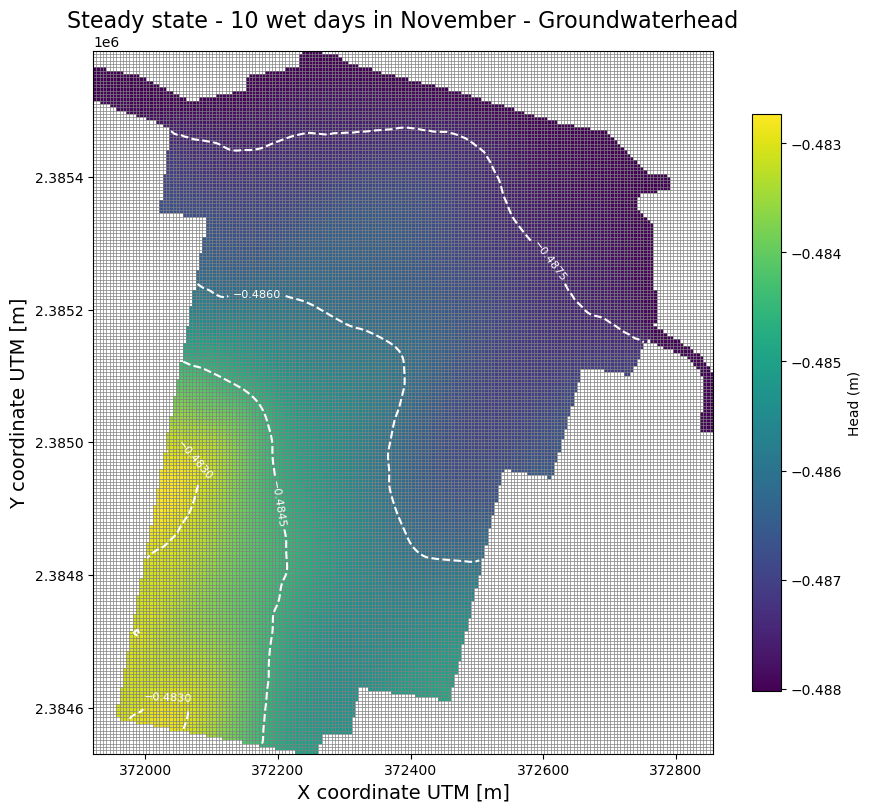

In [ ]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(1, 1, 1, aspect="equal")

pmv = flopy.plot.PlotMapView(model=gwf, ax=ax, layer=0)

pmv.plot_grid(colors="gray", lw=0.5)

map_head = pmv.plot_array(heads_steady, cmap="viridis")
plt.colorbar(map_head, shrink=0.75, label="Head (m)")

contours = pmv.contour_array(heads_steady, levels=3, colors="white")
plt.clabel(contours, inline=True, fontsize=8)

plt.title("Steady state - 10 wet days in November - Groundwaterhead", fontsize=16)
plt.xlabel('X coordinate UTM [m]', fontsize=14)
plt.ylabel('Y coordinate UTM [m]', fontsize=14)
plt.show()



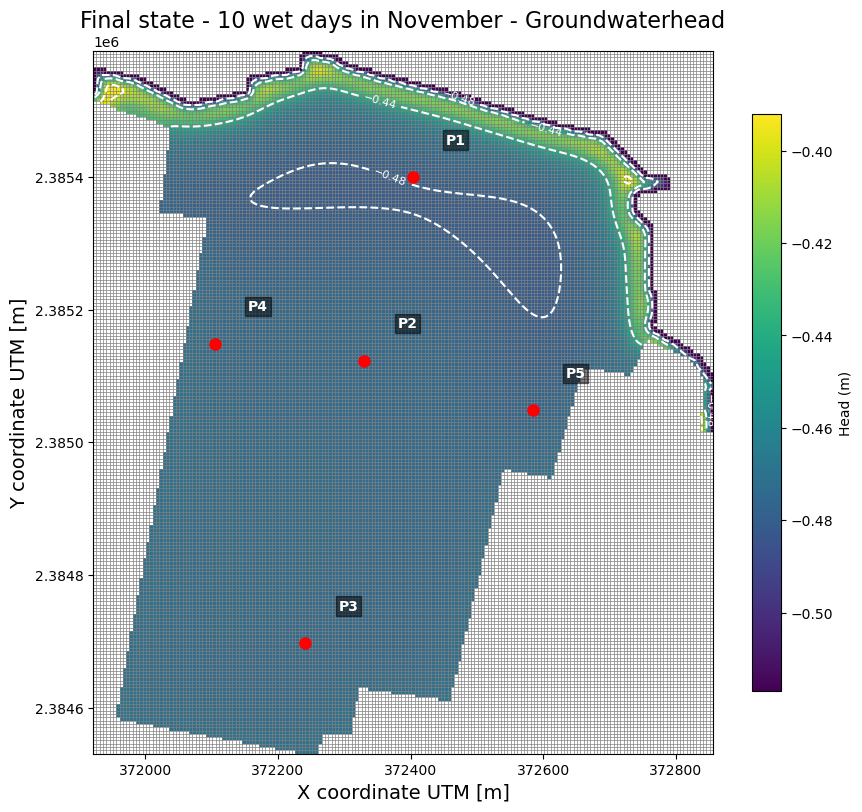

In [ ]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(1, 1, 1, aspect="equal")

pmv = flopy.plot.PlotMapView(model=gwf, ax=ax, layer=0)

pmv.plot_grid(colors="gray", lw=0.5)

map_head = pmv.plot_array(heads_final, cmap="viridis")
plt.colorbar(map_head, shrink=0.75, label="Head (m)")

contours = pmv.contour_array(heads_final, levels=3, colors="white")
plt.clabel(contours, inline=True, fontsize=8)

plt.title("Final state - 10 wet days in November - Groundwaterhead", fontsize=16)
plt.xlabel('X coordinate UTM [m]', fontsize=14)
plt.ylabel('Y coordinate UTM [m]', fontsize=14)

coords = {
    "P1": (372403, 2385400),
    "P2": (372330, 2385123),
    "P3": (372241, 2384697),
    "P4": (372105, 2385149),
    "P5": (372584, 2385048),
}

for obs_name, (x, y) in coords.items():
    ax.plot(x, y, marker="o", color="red", markersize=8, zorder=5)

    ax.text(
        x + 50,
        y + 50,
        obs_name,
        color="white",
        fontweight="bold",
        fontsize=10,
        bbox=dict(facecolor="black", alpha=0.5, pad=2),
        zorder=6,
    )
plt.show()



In [36]:
import matplotlib.colors as mcolors

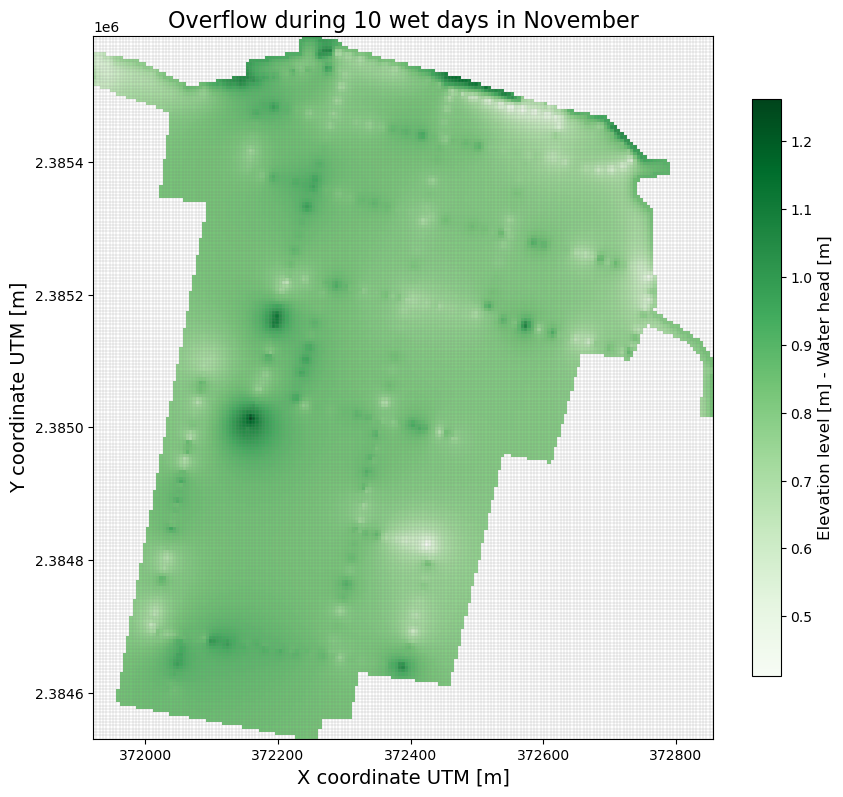

vmin is 0.412 en vmax is 1.263


In [ ]:

top_elev = np.round(gwf.dis.top.array, 3)
head_layer1 = np.round(heads_final[0], 3)

depth_to_water = top_elev - head_layer1

depth_to_water[np.abs(depth_to_water) > 1e4] = np.nan

is_flooded = head_layer1 >= top_elev

colors = ["darkred", "red", "lightcoral", "white", "lightgreen", "green", "darkgreen"]
custom_cmap = mcolors.LinearSegmentedColormap.from_list("red_green_dtw", colors)

vmin = np.nanmin(depth_to_water)
vmax = np.nanmax(depth_to_water)
norm = mcolors.TwoSlopeNorm(vmin=vmin, vcenter=vmin + 0.5*(vmax-vmin), vmax=vmax)

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(1, 1, 1, aspect="equal")

pmv = flopy.plot.PlotMapView(model=gwf, ax=ax, layer=0)
pmv.plot_grid(colors="gray", lw=0.3, alpha=0.5)

dtw_plot = pmv.plot_array(depth_to_water, cmap="Greens", norm=norm)

cb = plt.colorbar(dtw_plot, shrink=0.75)
cb.set_label('Elevation level [m] - Water head [m]', fontsize=12)

plt.title("Overflow during 10 wet days in November", fontsize=16)
plt.xlabel('X coordinate UTM [m]', fontsize=14)
plt.ylabel('Y coordinate UTM [m]', fontsize=14)
plt.show()

print(f'vmin is {vmin} en vmax is {vmax}')

In [39]:
import matplotlib.colors as mcolors

In [ ]:
idomain_layer1 = gwf.dis.idomain.array[0]

active_mask = (idomain_layer1 > 0) & (~np.isnan(top_elev))
flooded_mask = active_mask & (depth_to_water < 0.0)

rows, cols = np.where(flooded_mask)

grid = gwf.modelgrid

df_flooded = pd.DataFrame({
    "Row": rows,
    "Column": cols,
    "X": grid.xcellcenters[rows, cols],
    "Y": grid.ycellcenters[rows, cols],
    "Flood_Depth_m": np.abs(depth_to_water[rows, cols]),
    "Top_Elev_m": top_elev[rows, cols],
    "Head_m": head_layer1[rows, cols],
})

print(f"Aantal overstroomde cellen BINNEN studiegebied: {len(df_flooded)}")
print(df_flooded.to_string(index=False))

Aantal overstroomde cellen BINNEN studiegebied: 0
Empty DataFrame
Columns: [Row, Column, X, Y, Flood_Depth_m, Top_Elev_m, Head_m]
Index: []


## SE CREA EL ARCHIVO DE PYTHON SOBRE EL QUE SE VA A CALIBRAR

         time        P1        P2        P3        P4        P5
0         1.0 -0.486950 -0.485761 -0.485049 -0.484990 -0.486947
1        13.0 -0.486894 -0.485705 -0.484992 -0.484936 -0.486892
2        25.0 -0.486839 -0.485650 -0.484935 -0.484882 -0.486836
3        37.0 -0.486784 -0.485594 -0.484878 -0.484828 -0.486780
4        49.0 -0.486729 -0.485539 -0.484821 -0.484774 -0.486725
...       ...       ...       ...       ...       ...       ...
1201  14413.0 -0.479604 -0.473734 -0.473335 -0.473055 -0.476053
1202  14425.0 -0.479583 -0.473734 -0.473334 -0.473041 -0.476044
1203  14437.0 -0.479562 -0.473735 -0.473333 -0.473027 -0.476034
1204  14449.0 -0.479541 -0.473735 -0.473331 -0.473013 -0.476024
1205  14461.0 -0.479520 -0.473736 -0.473330 -0.472999 -0.476014

[1206 rows x 6 columns]


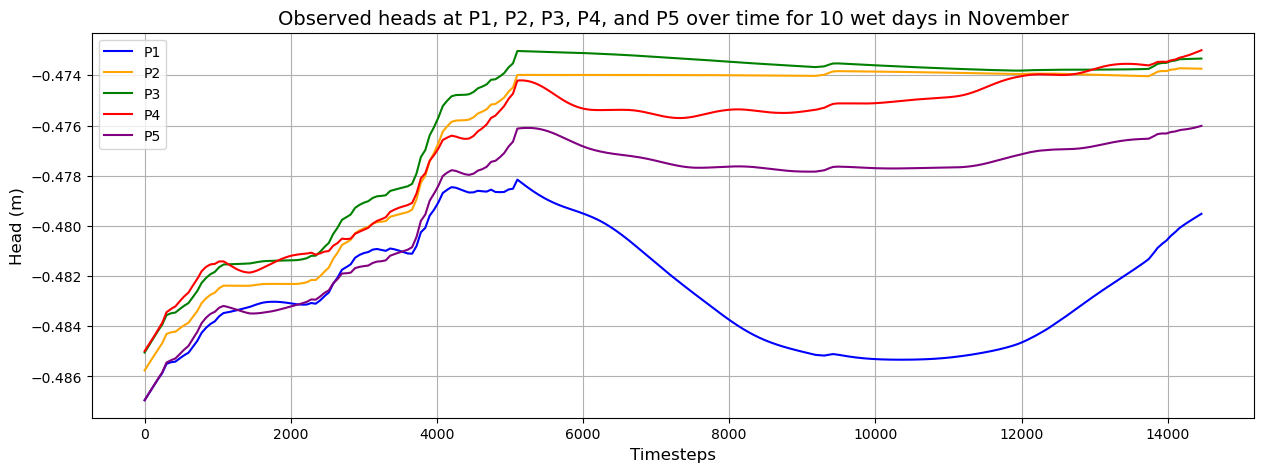

In [ ]:
ob = pd.read_csv('C:\SAN_FELIPE\SAN_FELIPE\model_wet\SAN_FELIPE.ob_gw_out_head.csv')
print(ob)

plt.figure(figsize=(15, 5))

plt.plot(ob["time"], ob["P1"], label="P1", color ='blue')
plt.plot(ob["time"], ob["P2"], label="P2", color ='orange')
plt.plot(ob["time"], ob["P3"], label="P3", color='green')
plt.plot(ob["time"], ob["P4"], label="P4", color='red')
plt.plot(ob["time"], ob["P5"], label="P5", color='purple')

plt.title("Observed heads at P1, P2, P3, P4, and P5 over time for 10 wet days in November", fontsize=14)
plt.xlabel("Timesteps", fontsize=12)
plt.ylabel("Head (m)", fontsize=12)
plt.legend()
plt.grid(True)

plt.show()

         time        P1        P2        P3        P4        P5
0         1.0 -0.486950 -0.485761 -0.485049 -0.484990 -0.486947
1        13.0 -0.486894 -0.485705 -0.484992 -0.484936 -0.486892
2        25.0 -0.486839 -0.485650 -0.484935 -0.484882 -0.486836
3        37.0 -0.486784 -0.485594 -0.484878 -0.484828 -0.486780
4        49.0 -0.486729 -0.485539 -0.484821 -0.484774 -0.486725
...       ...       ...       ...       ...       ...       ...
1201  14413.0 -0.479604 -0.473734 -0.473335 -0.473055 -0.476053
1202  14425.0 -0.479583 -0.473734 -0.473334 -0.473041 -0.476044
1203  14437.0 -0.479562 -0.473735 -0.473333 -0.473027 -0.476034
1204  14449.0 -0.479541 -0.473735 -0.473331 -0.473013 -0.476024
1205  14461.0 -0.479520 -0.473736 -0.473330 -0.472999 -0.476014

[1206 rows x 6 columns]


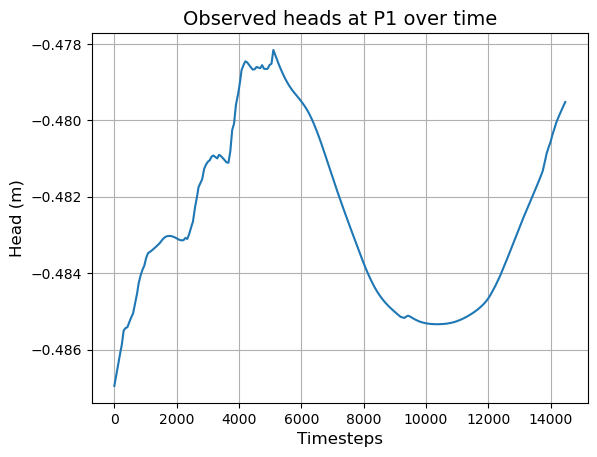

In [42]:
ob = pd.read_csv('C:\SAN_FELIPE\SAN_FELIPE\model_wet\SAN_FELIPE.ob_gw_out_head.csv')
plt.plot(ob['time'], ob['P1'])
plt.title('Observed heads at P1 over time', fontsize=14)
plt.xlabel('Timesteps', fontsize=12)
plt.ylabel('Head (m)', fontsize=12)
plt.grid()
print(ob)

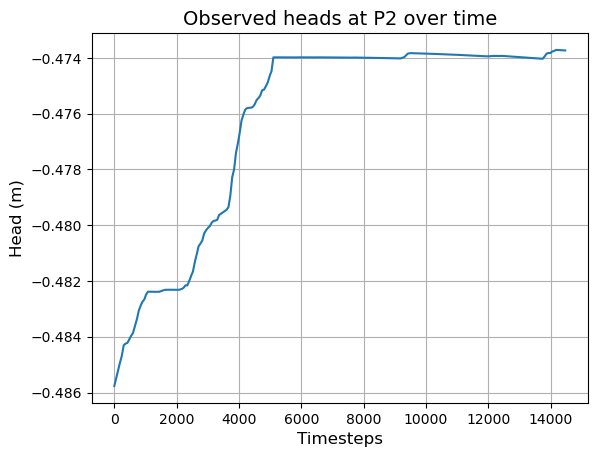

In [43]:
plt.plot(ob['time'], ob['P2'])
plt.title('Observed heads at P2 over time', fontsize=14)
plt.xlabel('Timesteps', fontsize=12)
plt.ylabel('Head (m)', fontsize=12)
plt.grid()

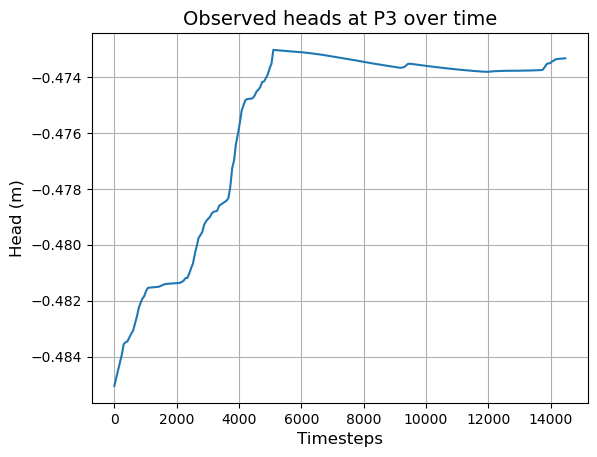

In [44]:
plt.plot(ob['time'], ob['P3'])
plt.title('Observed heads at P3 over time', fontsize=14)
plt.xlabel('Timesteps', fontsize=12)
plt.ylabel('Head (m)', fontsize=12)
plt.grid()

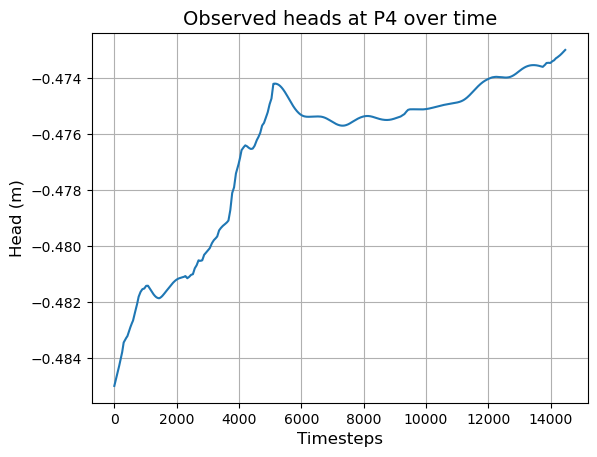

In [45]:
plt.plot(ob['time'], ob['P4'])
plt.title('Observed heads at P4 over time', fontsize=14)
plt.xlabel('Timesteps', fontsize=12)
plt.ylabel('Head (m)', fontsize=12)
plt.grid()